Notebook used for the individual EDA work. Detailed findings and interpretations are documented separately in the Data Exploration report.

In [1]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import networkx as nx

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

sns.set_theme(style="whitegrid", font_scale=0.95)
PALETTE = {"technical": "#2E5EAA", "methodology": "#D9822B", "soft": "#3F9D6E"}
plt.rcParams["figure.facecolor"] = "white"

df = pd.read_csv("cleaned_market_data.csv")
print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns.")

Loaded 8,129 rows and 20 columns.


Check the dataset structure, missing values, duplicates, and field cardinality.

In [2]:
skill_cols = [c for c in df.columns if c.startswith("Needs_")]
id_cols = ["job_link"]
descriptive_cols = [c for c in df.columns if c not in skill_cols + id_cols]

print("Skill (one-hot) columns:", len(skill_cols))
print(skill_cols)
print()
print("Descriptive columns:", descriptive_cols)
print()
print("Missing values per column:")
print(df.isnull().sum().to_string())
print()
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicated job_link (should be a unique key):", df["job_link"].duplicated().sum())
print()
print("Cardinality of each descriptive field:")
for c in descriptive_cols:
    print(f"  {c:18s} {df[c].nunique():>6,} unique values")

Skill (one-hot) columns: 13
['Needs_SQL', 'Needs_Python', 'Needs_R', 'Needs_Relational_DB', 'Needs_Tableau', 'Needs_PowerBI', 'Needs_Excel', 'Needs_Agile', 'Needs_Scrum', 'Needs_SDLC', 'Needs_Jira', 'Needs_Communication', 'Needs_ProblemSolving']

Descriptive columns: ['job_title', 'company', 'job_location', 'search_city', 'search_country', 'search_position']

Missing values per column:
job_link                0
job_title               0
company                 0
job_location            0
search_city             0
search_country          0
search_position         0
Needs_SQL               0
Needs_Python            0
Needs_R                 0
Needs_Relational_DB     0
Needs_Tableau           0
Needs_PowerBI           0
Needs_Excel             0
Needs_Agile             0
Needs_Scrum             0
Needs_SDLC              0
Needs_Jira              0
Needs_Communication     0
Needs_ProblemSolving    0

Fully duplicated rows: 0
Duplicated job_link (should be a unique key): 0

Cardinality of e

Create helper variables used to group titles, locations, seniority signals, and skill counts.

In [3]:
STATE_ABBR = {
    "Alabama": "AL", "Alaska": "AK", "Arizona": "AZ", "Arkansas": "AR", "California": "CA",
    "Colorado": "CO", "Connecticut": "CT", "Delaware": "DE", "District of Columbia": "DC",
    "Florida": "FL", "Georgia": "GA", "Hawaii": "HI", "Idaho": "ID", "Illinois": "IL",
    "Indiana": "IN", "Iowa": "IA", "Kansas": "KS", "Kentucky": "KY", "Louisiana": "LA",
    "Maine": "ME", "Maryland": "MD", "Massachusetts": "MA", "Michigan": "MI", "Minnesota": "MN",
    "Mississippi": "MS", "Missouri": "MO", "Montana": "MT", "Nebraska": "NE", "Nevada": "NV",
    "New Hampshire": "NH", "New Jersey": "NJ", "New Mexico": "NM", "New York": "NY",
    "North Carolina": "NC", "North Dakota": "ND", "Ohio": "OH", "Oklahoma": "OK", "Oregon": "OR",
    "Pennsylvania": "PA", "Rhode Island": "RI", "South Carolina": "SC", "South Dakota": "SD",
    "Tennessee": "TN", "Texas": "TX", "Utah": "UT", "Vermont": "VT", "Virginia": "VA",
    "Washington": "WA", "West Virginia": "WV", "Wisconsin": "WI", "Wyoming": "WY",
}

def extract_state(loc):
    """Pull a 2-letter US state code out of the various job_location formats."""
    if pd.isna(loc):
        return "Not specified"
    loc = loc.strip()
    m = re.match(r"^[A-Za-z\.\-' ]+,\s*([A-Z]{2})$", loc)          # "City, ST"
    if m:
        return m.group(1)
    m2 = re.match(r"^([A-Za-z ]+),\s*United States$", loc)          # "State, United States"
    if m2 and m2.group(1).strip() in STATE_ABBR:
        return STATE_ABBR[m2.group(1).strip()]
    return "Not specified"                                          # metro names, "United States" alone, etc.

def categorize_title(title):
    """Bucket a raw job title into a small set of BA-adjacent role families."""
    t = title.lower()
    if "business intelligence" in t or re.search(r"\bbi analyst\b", t):
        return "Business Intelligence Analyst"
    if "business systems analyst" in t:
        return "Systems/Business Systems Analyst"
    if "financial" in t and "analyst" in t:
        return "Financial Analyst"
    if "business process analyst" in t or ("process" in t and "analyst" in t):
        return "Business Process Analyst"
    if "data analyst" in t or "data analytics" in t:
        return "Data Analyst"
    if "systems analyst" in t or "system analyst" in t:
        return "Systems/Business Systems Analyst"
    if "business analyst" in t:
        return "Business Analyst (general)"
    return "Other/Specialized Analyst"

def tag_seniority(title):
    """Very rough seniority read from title text only -- not a real experience-level field."""
    t = title.lower()
    if re.search(r"\b(senior|sr\.?|principal|staff|lead)\b", t):
        return "Senior/Lead+"
    if re.search(r"\b(manager|director)\b", t):
        return "Manager/Director"
    if re.search(r"\b(junior|jr\.?|entry|associate)\b", t):
        return "Entry/Junior"
    return "Not stated in title"

df["state"] = df["job_location"].apply(extract_state)
df["title_family"] = df["job_title"].apply(categorize_title)
df["seniority_hint"] = df["job_title"].apply(tag_seniority)
df["n_skills"] = df[skill_cols].sum(axis=1)

print("State parsed successfully for {:.1f}% of postings ({:,} of {:,}); the rest were multi-state "
      "or metro-area entries bucketed as 'Not specified'.".format(
          (df["state"] != "Not specified").mean() * 100,
          (df["state"] != "Not specified").sum(), len(df)))
print()
print("title_family counts:")
print(df["title_family"].value_counts().to_string())
print()
print("seniority_hint counts:")
print(df["seniority_hint"].value_counts().to_string())

State parsed successfully for 97.4% of postings (7,914 of 8,129); the rest were multi-state or metro-area entries bucketed as 'Not specified'.

title_family counts:
title_family
Business Analyst (general)          3509
Data Analyst                        1479
Systems/Business Systems Analyst    1316
Other/Specialized Analyst           1177
Business Intelligence Analyst        277
Financial Analyst                    208
Business Process Analyst             163

seniority_hint counts:
seniority_hint
Not stated in title    5447
Senior/Lead+           2498
Entry/Junior            112
Manager/Director         72


Compare grouped title families with the most common raw job titles.

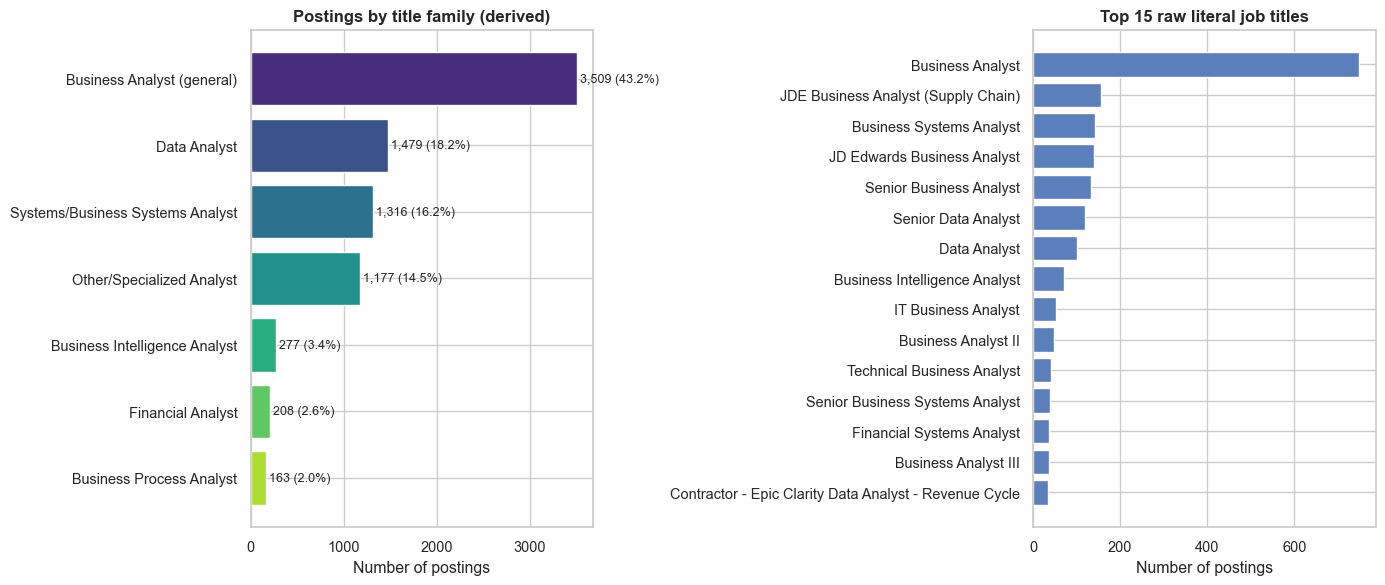

Reality check on the 'Other/Specialized Analyst' bucket -- its 15 most common raw titles:
job_title
Contracts Lifecycle Management (CLM) Functional Analyst - Senior Associate    32
Senior Systems Engineer                                                       31
Senior Data Engineer                                                          23
Senior Backend Engineer                                                       13
Lead Data Engineer                                                            11
Functional Analyst                                                            10
Specialist                                                                     8
Lead Systems Engineer                                                          8
Information Security Analyst                                                   6
Systems Engineer                                                               5
Senior Windows Engineer                                                        5
Senior So

In [4]:
fam_counts = df["title_family"].value_counts()
raw_counts = df["job_title"].value_counts().head(15)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

colors_fam = sns.color_palette("viridis", len(fam_counts))
axes[0].barh(fam_counts.index[::-1], fam_counts.values[::-1], color=colors_fam[::-1])
axes[0].set_title("Postings by title family (derived)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Number of postings")
for i, v in enumerate(fam_counts.values[::-1]):
    axes[0].text(v + 30, i, f"{v:,} ({v/len(df)*100:.1f}%)", va="center", fontsize=9)

axes[1].barh(raw_counts.index[::-1], raw_counts.values[::-1], color="#5b7fbd")
axes[1].set_title("Top 15 raw literal job titles", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Number of postings")

plt.tight_layout()
plt.show()

print("Reality check on the 'Other/Specialized Analyst' bucket -- its 15 most common raw titles:")
print(df.loc[df["title_family"] == "Other/Specialized Analyst", "job_title"].value_counts().head(15).to_string())

Explore posting volume by company and U.S. state, plus title-family composition by state.

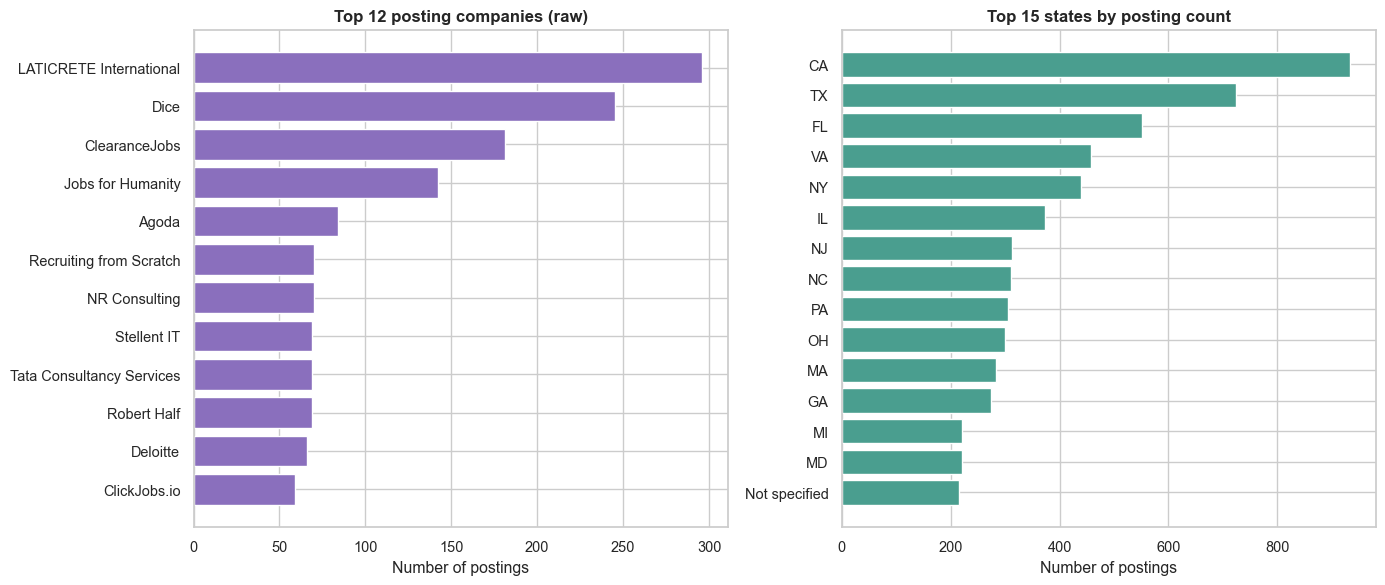

Top 10 states account for 57.9% of all postings.


In [5]:
top_companies = df["company"].value_counts().head(12)
top_states = df["state"].value_counts().head(15)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].barh(top_companies.index[::-1], top_companies.values[::-1], color="#8a6fbd")
axes[0].set_title("Top 12 posting companies (raw)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Number of postings")

axes[1].barh(top_states.index[::-1], top_states.values[::-1], color="#4a9e8f")
axes[1].set_title("Top 15 states by posting count", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Number of postings")

plt.tight_layout()
plt.show()

top10_share = df["state"].value_counts().head(10).sum() / len(df) * 100
print(f"Top 10 states account for {top10_share:.1f}% of all postings.")

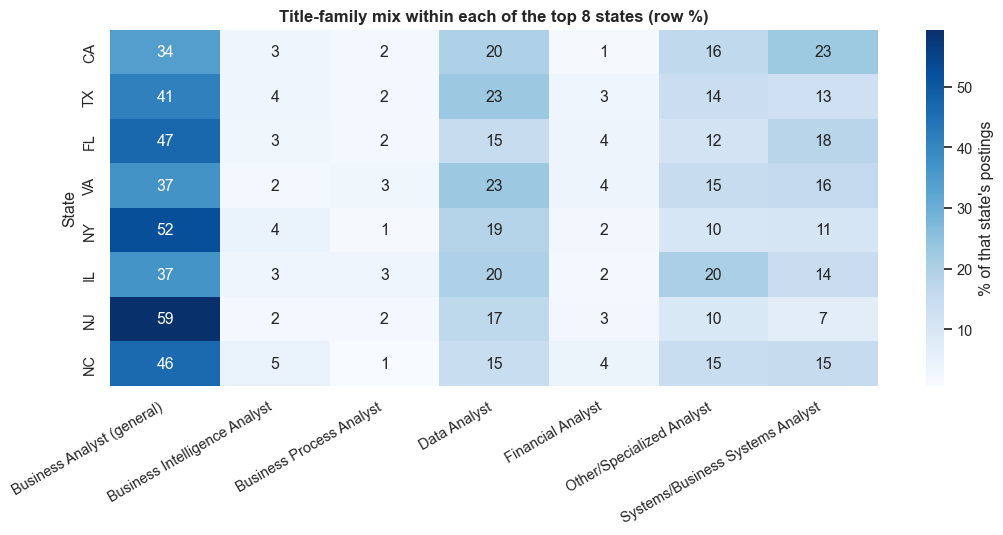

In [6]:
top8_states = df["state"].value_counts().head(8).index.tolist()
sub = df[df["state"].isin(top8_states)]
comp = pd.crosstab(sub["state"], sub["title_family"], normalize="index") * 100
comp = comp.loc[top8_states]

fig, ax = plt.subplots(figsize=(11, 5.5))
sns.heatmap(comp, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% of that state's postings"}, ax=ax)
ax.set_title("Title-family mix within each of the top 8 states (row %)", fontsize=12, fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel("State")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

Calculate prevalence of the 13 tracked skill indicators.

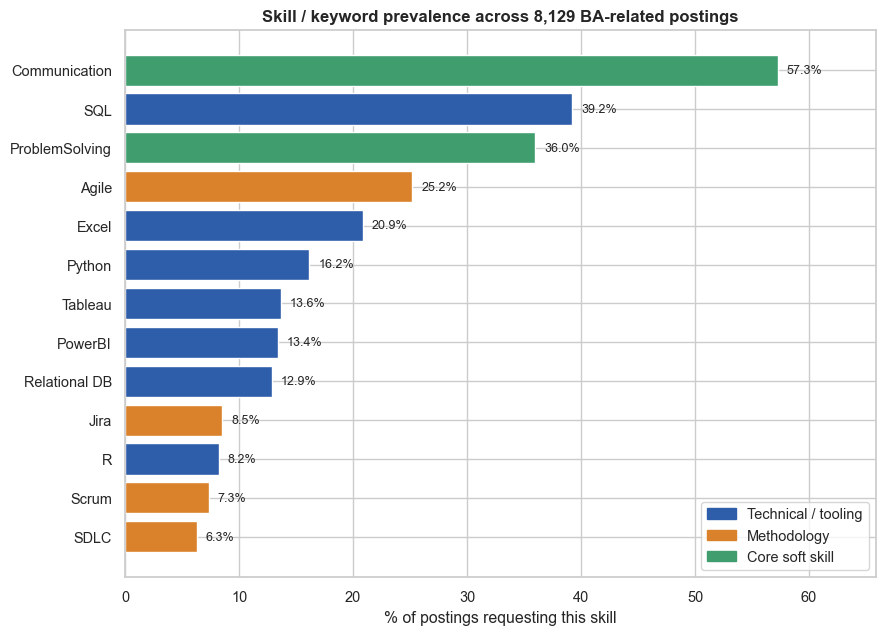

Needs_Communication     57.3
Needs_SQL               39.2
Needs_ProblemSolving    36.0
Needs_Agile             25.2
Needs_Excel             20.9
Needs_Python            16.2
Needs_Tableau           13.6
Needs_PowerBI           13.4
Needs_Relational_DB     12.9
Needs_Jira               8.5
Needs_R                  8.2
Needs_Scrum              7.3
Needs_SDLC               6.3


In [7]:
SKILL_GROUP = {
    "Needs_SQL": "technical", "Needs_Python": "technical", "Needs_R": "technical",
    "Needs_Relational_DB": "technical", "Needs_Tableau": "technical", "Needs_PowerBI": "technical",
    "Needs_Excel": "technical",
    "Needs_Agile": "methodology", "Needs_Scrum": "methodology", "Needs_SDLC": "methodology",
    "Needs_Jira": "methodology",
    "Needs_Communication": "soft", "Needs_ProblemSolving": "soft",
}
LABELS = {c: c.replace("Needs_", "").replace("_", " ") for c in skill_cols}

prevalence = (df[skill_cols].mean() * 100).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 6.5))
colors = [PALETTE[SKILL_GROUP[c]] for c in prevalence.index]
ax.barh([LABELS[c] for c in prevalence.index][::-1], prevalence.values[::-1], color=colors[::-1])
for i, v in enumerate(prevalence.values[::-1]):
    ax.text(v + 0.8, i, f"{v:.1f}%", va="center", fontsize=9)
ax.set_xlabel("% of postings requesting this skill")
ax.set_title("Skill / keyword prevalence across 8,129 BA-related postings", fontsize=12, fontweight="bold")
ax.set_xlim(0, prevalence.max() * 1.15)

handles = [plt.Rectangle((0, 0), 1, 1, color=PALETTE[g]) for g in ["technical", "methodology", "soft"]]
ax.legend(handles, ["Technical / tooling", "Methodology", "Core soft skill"], loc="lower right", frameon=True)
plt.tight_layout()
plt.show()

print(prevalence.round(1).to_string())

Examine the distribution of skill counts and postings with zero tracked skills.

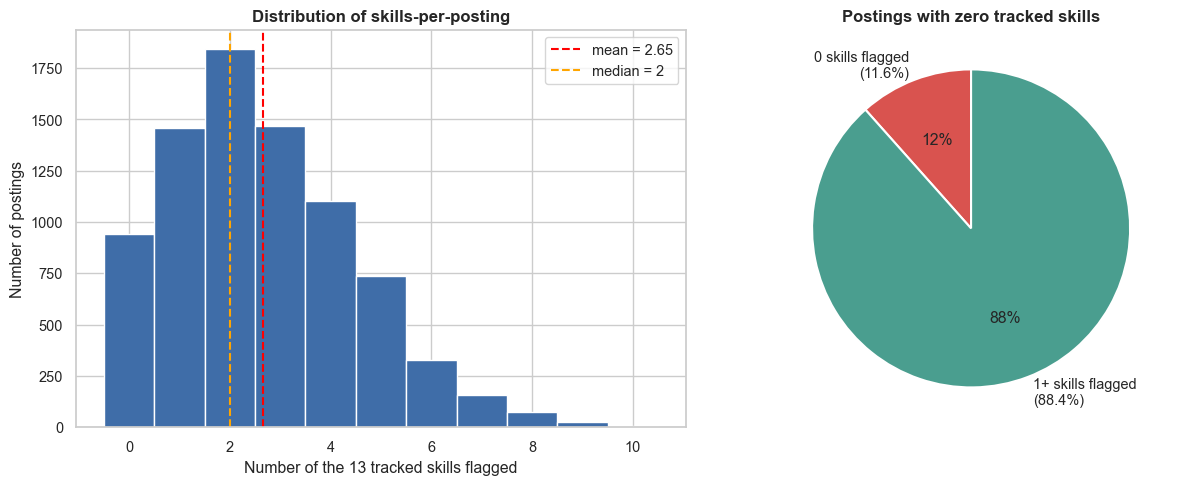

count    8129.00
mean        2.65
std         1.84
min         0.00
25%         1.00
50%         2.00
75%         4.00
max        10.00


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(df["n_skills"], bins=range(0, 12), color="#3F6DA8", edgecolor="white", align="left")
axes[0].axvline(df["n_skills"].mean(), color="red", linestyle="--", linewidth=1.5, label=f"mean = {df['n_skills'].mean():.2f}")
axes[0].axvline(df["n_skills"].median(), color="orange", linestyle="--", linewidth=1.5, label=f"median = {df['n_skills'].median():.0f}")
axes[0].set_xlabel("Number of the 13 tracked skills flagged")
axes[0].set_ylabel("Number of postings")
axes[0].set_title("Distribution of skills-per-posting", fontsize=12, fontweight="bold")
axes[0].legend()

zero_pct = (df["n_skills"] == 0).mean() * 100
axes[1].pie([zero_pct, 100 - zero_pct],
            labels=[f"0 skills flagged\n({zero_pct:.1f}%)", f"1+ skills flagged\n({100 - zero_pct:.1f}%)"],
            colors=["#D9534F", "#4a9e8f"], autopct=lambda p: f"{p:.0f}%", startangle=90,
            wedgeprops={"edgecolor": "white", "linewidth": 1.5})
axes[1].set_title("Postings with zero tracked skills", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

print(df["n_skills"].describe().round(2).to_string())

Calculate pairwise correlations and cluster the skill variables for visual inspection.

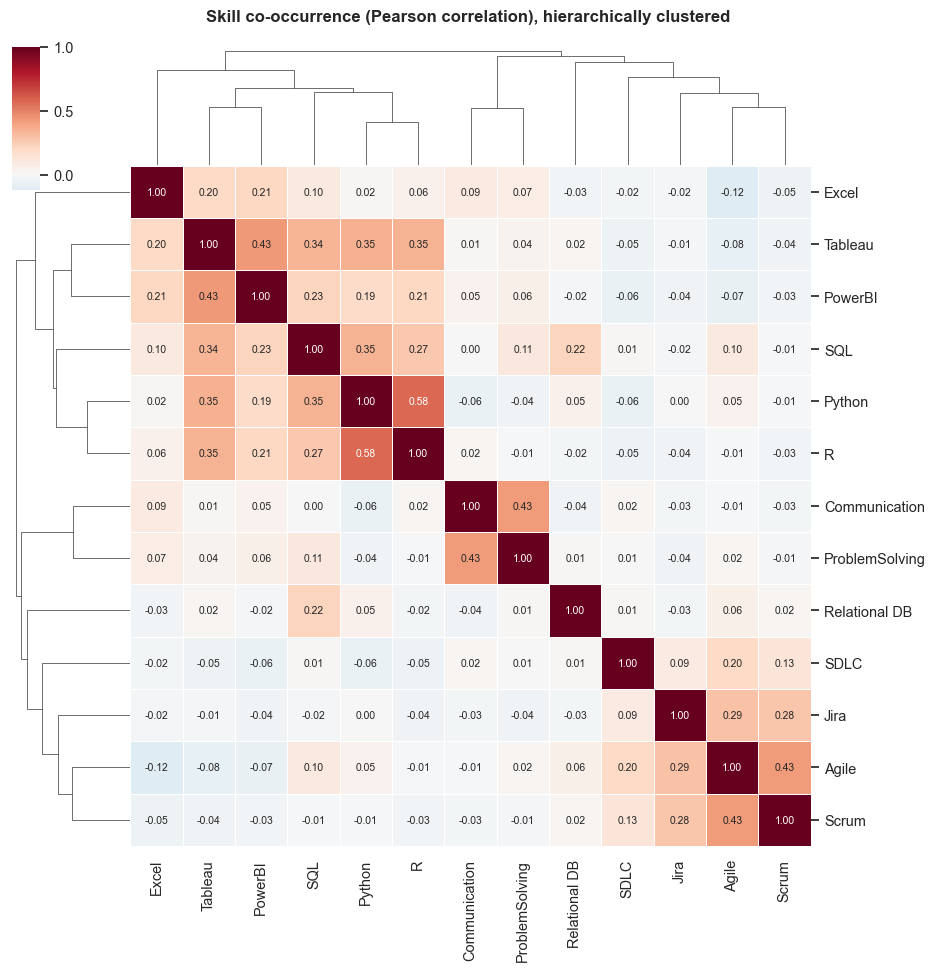

Strongest positive pairs:
Python         R                 0.576
Tableau        PowerBI           0.434
Agile          Scrum             0.425
Communication  ProblemSolving    0.425
Python         Tableau           0.354
R              Tableau           0.352
SQL            Python            0.350
               Tableau           0.340

Most negative / least compatible pairs:
Python   Communication   -0.062
PowerBI  SDLC            -0.065
         Agile           -0.074
Tableau  Agile           -0.083
Excel    Agile           -0.118


In [9]:
corr = df[skill_cols].corr()
corr.columns = corr.index = [LABELS[c] for c in corr.columns]

g = sns.clustermap(corr, cmap="RdBu_r", center=0, annot=True, fmt=".2f", figsize=(9.5, 9.5),
                    cbar_pos=(0.02, 0.83, 0.03, 0.15), dendrogram_ratio=0.15,
                    linewidths=0.4, annot_kws={"size": 7.5})
g.fig.suptitle("Skill co-occurrence (Pearson correlation), hierarchically clustered", y=1.02, fontsize=12, fontweight="bold")
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().dropna().sort_values(ascending=False)
print("Strongest positive pairs:")
print(pairs.head(8).round(3).to_string())
print()
print("Most negative / least compatible pairs:")
print(pairs.tail(5).round(3).to_string())

Represent correlations between skills as a network.

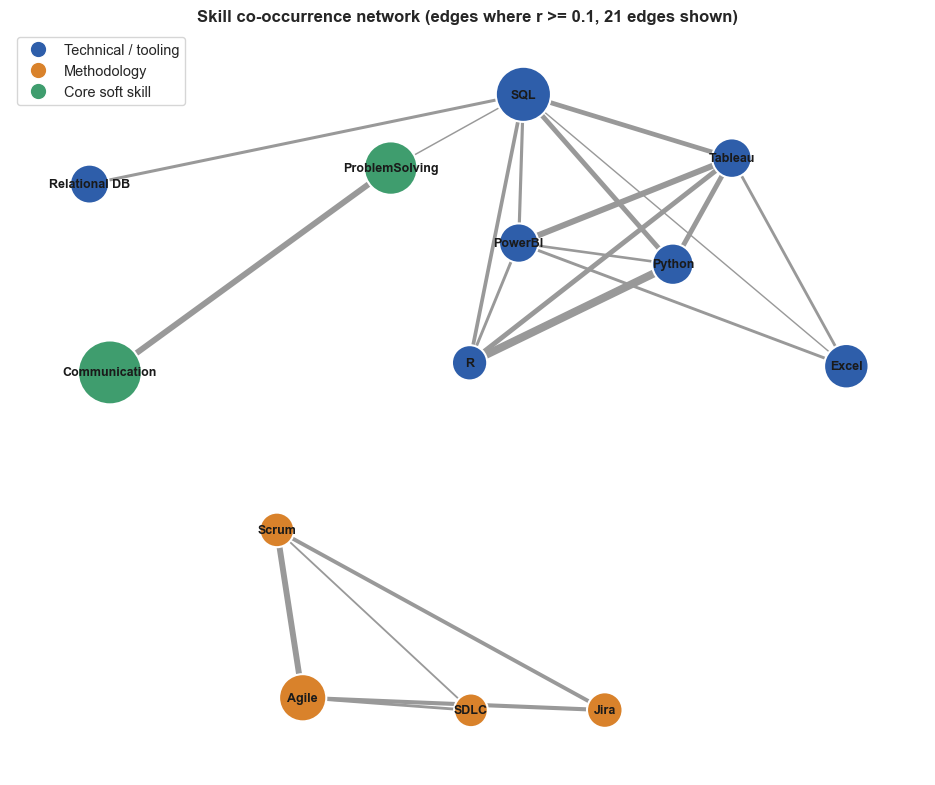

In [10]:
G = nx.Graph()
prevalence_frac = df[skill_cols].mean()
for c in skill_cols:
    G.add_node(LABELS[c], group=SKILL_GROUP[c], size=prevalence_frac[c])

THRESHOLD = 0.10
edge_count = 0
for i, c1 in enumerate(skill_cols):
    for c2 in skill_cols[i + 1:]:
        w = corr.loc[LABELS[c1], LABELS[c2]]
        if w >= THRESHOLD:
            G.add_edge(LABELS[c1], LABELS[c2], weight=w)
            edge_count += 1

pos = nx.spring_layout(G, seed=42, k=0.9, weight="weight")

fig, ax = plt.subplots(figsize=(9.5, 8))
node_sizes = [3000 * G.nodes[n]["size"] + 400 for n in G.nodes]
node_colors = [PALETTE[G.nodes[n]["group"]] for n in G.nodes]
edge_widths = [G[u][v]["weight"] * 10 for u, v in G.edges]

nx.draw_networkx_edges(G, pos, width=edge_widths, edge_color="#999999", ax=ax)
nx.draw_networkx_nodes(G, pos, node_size=node_sizes, node_color=node_colors, edgecolors="white", linewidths=1.5, ax=ax)
nx.draw_networkx_labels(G, pos, font_size=9, font_weight="bold", ax=ax)

handles = [plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=PALETTE[g], markersize=12, label=l)
           for g, l in [("technical", "Technical / tooling"), ("methodology", "Methodology"), ("soft", "Core soft skill")]]
ax.legend(handles=handles, loc="upper left", frameon=True)
ax.set_title(f"Skill co-occurrence network (edges where r >= {THRESHOLD}, {edge_count} edges shown)", fontsize=12, fontweight="bold")
ax.axis("off")
plt.tight_layout()
plt.show()

Compare skill prevalence across the derived title families.

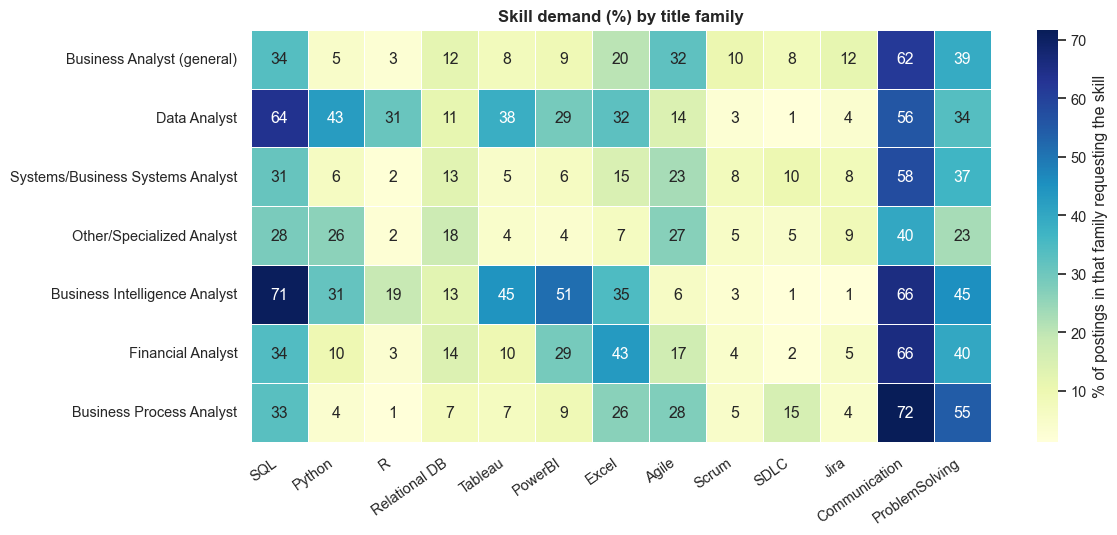

                                   SQL  Python     R  Relational DB  Tableau  PowerBI  Excel  Agile  Scrum  SDLC  Jira  Communication  ProblemSolving
title_family                                                                                                                                         
Business Analyst (general)        33.6     5.0   2.7           12.1      7.7      9.0   20.3   32.1   10.3   7.9  11.5           61.6            39.2
Data Analyst                      63.8    42.7  31.0           11.4     38.3     29.0   32.4   14.3    2.7   1.3   3.7           55.7            33.7
Systems/Business Systems Analyst  31.1     6.5   1.8           12.9      4.9      6.2   15.0   22.9    7.8   9.9   8.4           57.8            36.6
Other/Specialized Analyst         28.5    26.2   2.5           17.6      4.4      3.9    6.6   26.6    5.4   4.6   8.7           40.0            22.9
Business Intelligence Analyst     71.1    31.4  18.8           12.6     44.8     51.3   34.7    5.8 

In [11]:
family_order = df["title_family"].value_counts().index.tolist()
skill_by_family = (df.groupby("title_family")[skill_cols].mean() * 100).loc[family_order]
skill_by_family.columns = [LABELS[c] for c in skill_by_family.columns]

fig, ax = plt.subplots(figsize=(12, 5.5))
sns.heatmap(skill_by_family, annot=True, fmt=".0f", cmap="YlGnBu", linewidths=0.4,
            cbar_kws={"label": "% of postings in that family requesting the skill"}, ax=ax)
ax.set_title("Skill demand (%) by title family", fontsize=12, fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel("")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

print(skill_by_family.round(1).to_string())

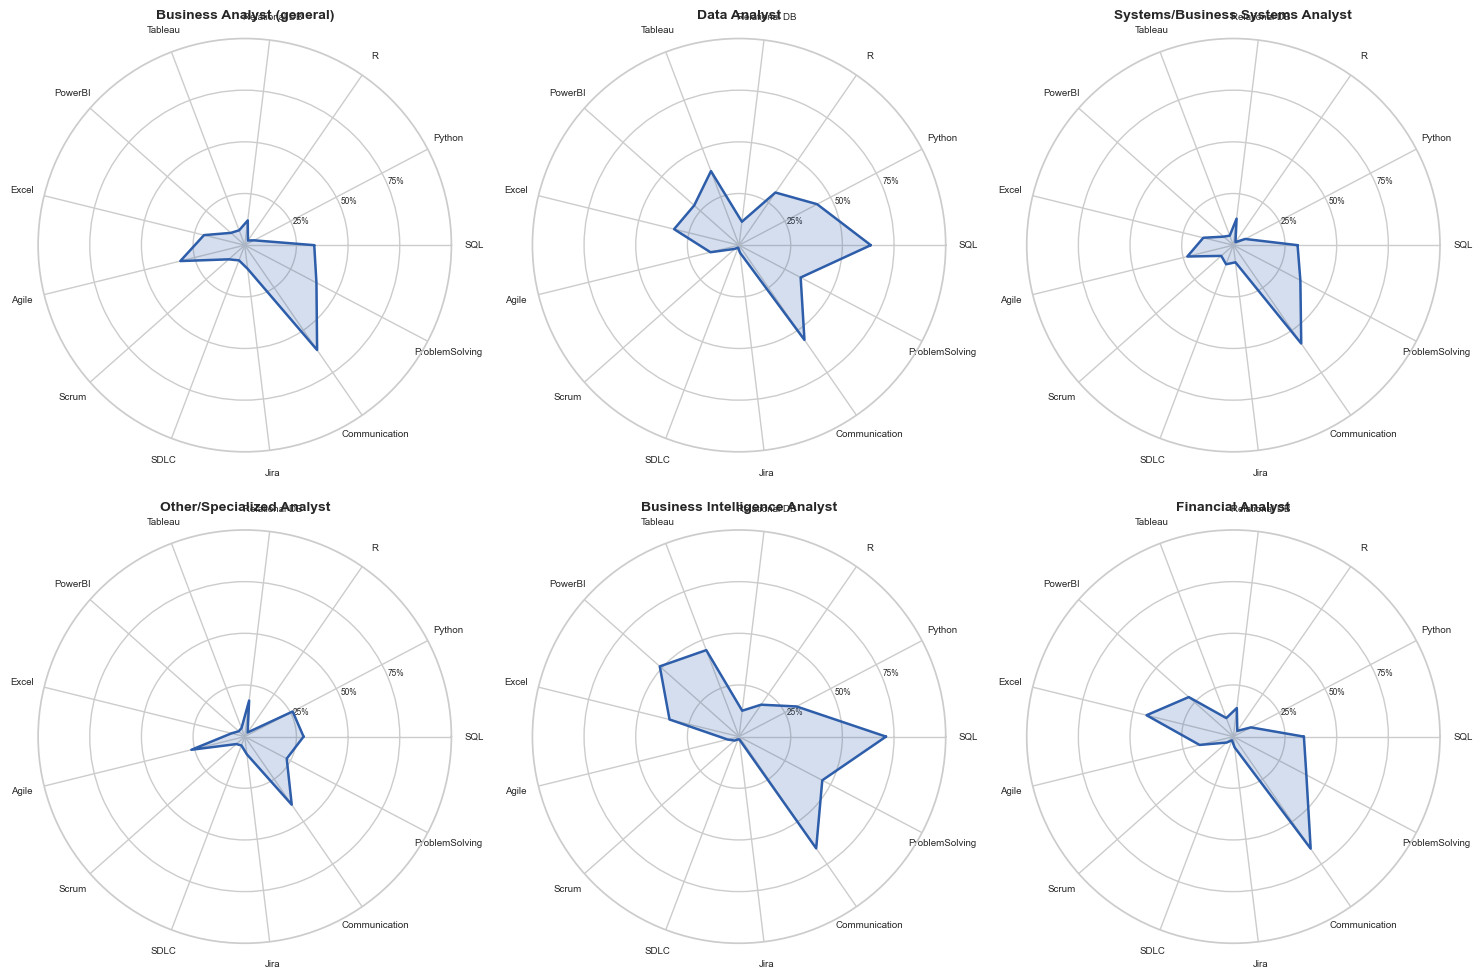

In [12]:
top_families = family_order[:6]
angles = np.linspace(0, 2 * np.pi, len(skill_cols), endpoint=False).tolist()
angles += angles[:1]

fig, axes = plt.subplots(2, 3, figsize=(15, 10), subplot_kw={"projection": "polar"})
axes = axes.flatten()

for ax, fam in zip(axes, top_families):
    vals = (df.loc[df["title_family"] == fam, skill_cols].mean() * 100).tolist()
    vals += vals[:1]
    ax.plot(angles, vals, color="#2E5EAA", linewidth=1.8)
    ax.fill(angles, vals, color="#2E5EAA", alpha=0.2)
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels([LABELS[c] for c in skill_cols], fontsize=7)
    ax.set_ylim(0, 100)
    ax.set_yticks([25, 50, 75])
    ax.set_yticklabels(["25%", "50%", "75%"], fontsize=6)
    ax.set_title(fam, fontsize=10, fontweight="bold", pad=14)

plt.tight_layout()
plt.show()

Use K-means on the standardised skill matrix and evaluate candidate values of k.

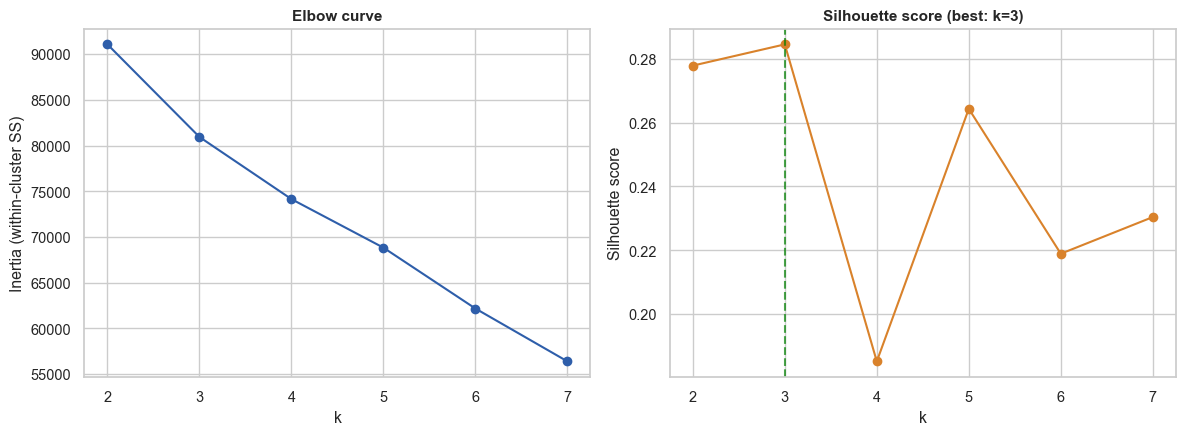

k=2: inertia=91,062, silhouette=0.278
k=3: inertia=80,931, silhouette=0.285
k=4: inertia=74,134, silhouette=0.185
k=5: inertia=68,821, silhouette=0.264
k=6: inertia=62,163, silhouette=0.219
k=7: inertia=56,382, silhouette=0.230


In [13]:
X = df[skill_cols].values
Xs = StandardScaler().fit_transform(X)

ks = list(range(2, 8))
inertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xs)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(Xs, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(ks, inertias, marker="o", color="#2E5EAA")
axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia (within-cluster SS)")
axes[0].set_title("Elbow curve", fontsize=11, fontweight="bold")

best_k = ks[int(np.argmax(sils))]
axes[1].plot(ks, sils, marker="o", color="#D9822B")
axes[1].axvline(best_k, color="green", linestyle="--", alpha=0.7)
axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette score")
axes[1].set_title(f"Silhouette score (best: k={best_k})", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.show()

for k, i, s in zip(ks, inertias, sils):
    print(f"k={k}: inertia={i:,.0f}, silhouette={s:.3f}")

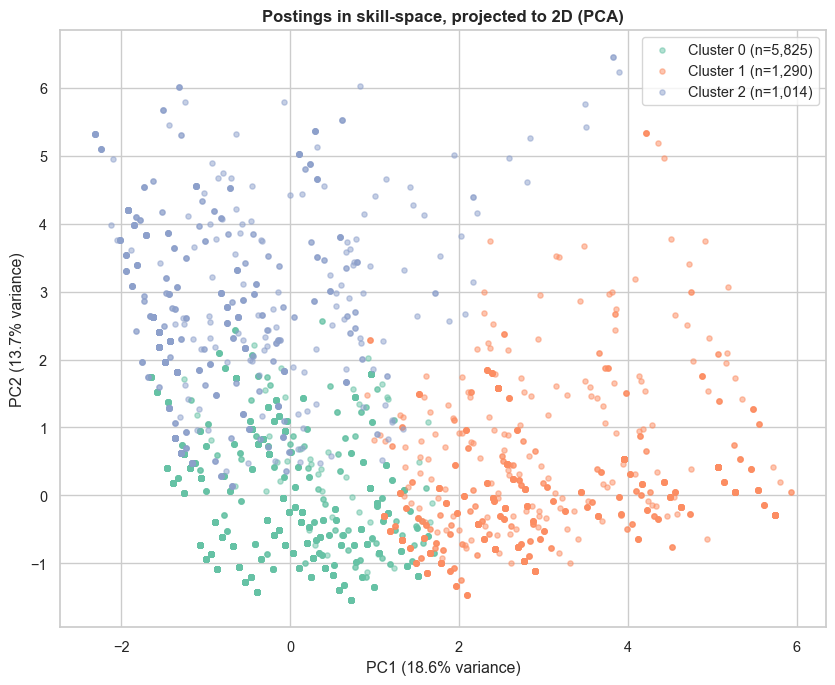

First 2 PCA components explain 32.3% of total variance across the 13 skill dimensions -- a partial view, not the full picture.

Mean skill prevalence (%) by cluster:
                SQL  Python     R  Relational DB  Tableau  PowerBI  Excel  Agile  Scrum  SDLC  Jira  Communication  ProblemSolving
skill_cluster                                                                                                                     
0              30.2     6.6   0.8           13.0      1.2      6.8   18.5   18.0    0.0   5.8   0.0           57.3            36.4
1              86.1    63.5  47.4           13.5     76.4     49.5   36.4   17.7    1.9   1.4   3.2           60.5            37.9
2              31.6    11.0   1.3           11.4      5.4      5.1   14.6   76.4   56.3  15.2  64.3           52.8            31.1


In [14]:
K_FINAL = 3
km = KMeans(n_clusters=K_FINAL, random_state=42, n_init=10).fit(Xs)
df["skill_cluster"] = km.labels_

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(Xs)
df["pca1"], df["pca2"] = coords[:, 0], coords[:, 1]

fig, ax = plt.subplots(figsize=(8.5, 7))
cluster_palette = sns.color_palette("Set2", K_FINAL)
for cl in range(K_FINAL):
    mask = df["skill_cluster"] == cl
    ax.scatter(df.loc[mask, "pca1"], df.loc[mask, "pca2"], s=14, alpha=0.5,
               color=cluster_palette[cl], label=f"Cluster {cl} (n={mask.sum():,})")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
ax.set_title("Postings in skill-space, projected to 2D (PCA)", fontsize=12, fontweight="bold")
ax.legend(frameon=True)
plt.tight_layout()
plt.show()

print(f"First 2 PCA components explain {pca.explained_variance_ratio_.sum()*100:.1f}% of total variance "
      f"across the 13 skill dimensions -- a partial view, not the full picture.")
print()
profile = (df.groupby("skill_cluster")[skill_cols].mean() * 100).round(1)
profile.columns = [LABELS[c] for c in profile.columns]
print("Mean skill prevalence (%) by cluster:")
print(profile.to_string())

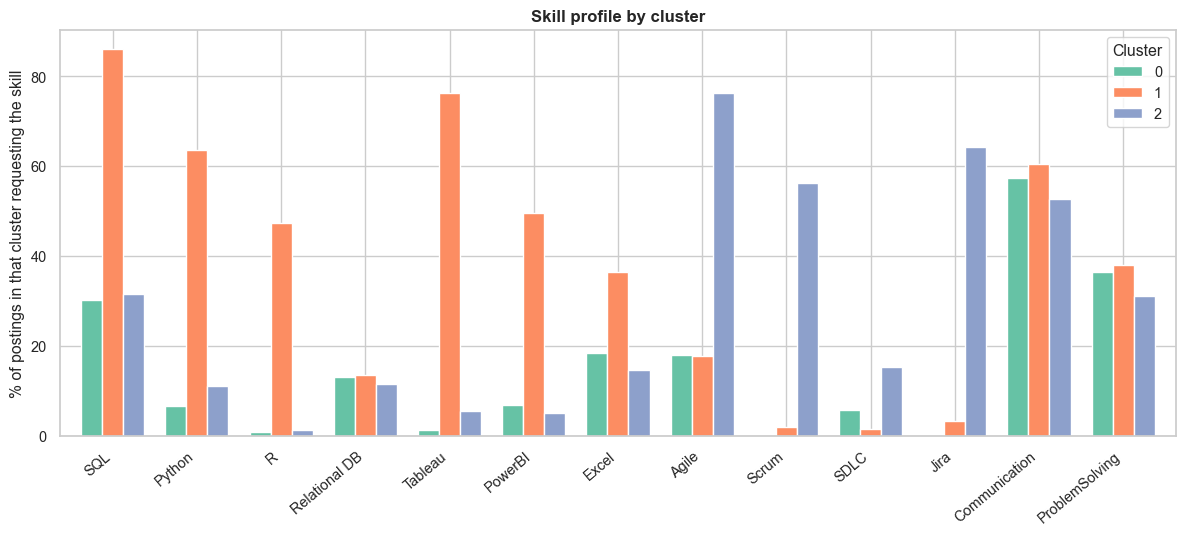

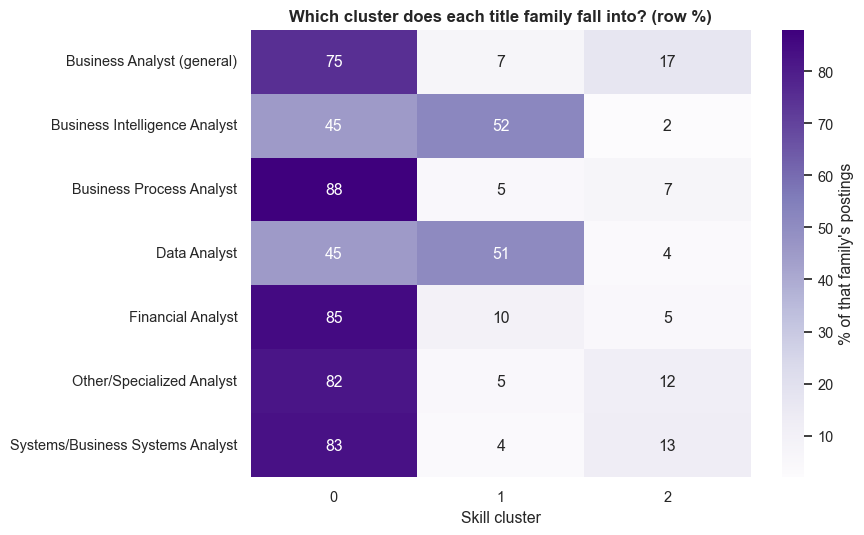

skill_cluster
0    71.7
1    15.9
2    12.5


In [15]:
fig, ax = plt.subplots(figsize=(12, 5.5))
profile.T.plot(kind="bar", ax=ax, color=cluster_palette, width=0.75)
ax.set_ylabel("% of postings in that cluster requesting the skill")
ax.set_title("Skill profile by cluster", fontsize=12, fontweight="bold")
ax.legend(title="Cluster")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

ct = pd.crosstab(df["title_family"], df["skill_cluster"], normalize="index") * 100
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.heatmap(ct.round(0), annot=True, fmt=".0f", cmap="Purples", cbar_kws={"label": "% of that family's postings"}, ax=ax)
ax.set_title("Which cluster does each title family fall into? (row %)", fontsize=12, fontweight="bold")
ax.set_xlabel("Skill cluster")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

print(df["skill_cluster"].value_counts(normalize=True).mul(100).round(1).to_string())